![Python Banner](../../Image/05_03_uplift_learners.png)


# 3.3 Uplift Random Forest Regression



## Overview

A standard predictive model asks: *"What outcome do we expect for this unit?"*

An **uplift model** asks a different question:

> *"How much would the outcome change **because of the treatment** for this unit, given their covariates?"*

That quantity is the **Conditional Average Treatment Effect (CATE)**. For a unit with covariates $X = x$ and a continuous outcome $Y$:

$$\tau(x) = \mathbb{E}[Y \mid T = 1, X = x] - \mathbb{E}[Y \mid T = 0, X = x]$$

where $T = 1$ is treated and $T = 0$ is control. **Heterogeneity** means $\tau(x)$ varies with $x$: some subgroups benefit strongly, others barely, and some may be harmed.

For **binary outcomes** (e.g. conversion yes/no), the CATE is:

$$\tau(x) = P(Y = 1 \mid T = 1, X = x) - P(Y = 1 \mid T = 0, X = x)$$

## Why an ensemble? From single trees to forests

A single uplift **tree** partitions covariate space into regions and assigns each a local treatment-effect estimate. This is interpretable, but unstable — small changes in data can produce very different splits.

An uplift random **forest** improves stability by **bagging** (bootstrap aggregating) many trees:

1. Draw a bootstrap sample of the training data.
2. Fit one uplift tree on that sample using a **treatment-aware splitting rule**.
3. Repeat for $B$ trees (`n_trees` in `UpliftRandomForest`).
4. For a new unit $x$, average leaf-level CATE estimates across all trees:

$$\hat{\tau}(x) = \frac{1}{B} \sum_{b=1}^{B} \hat{\tau}_b(x)$$

Averaging reduces variance and produces more reliable ranking of units by uplift than a single tree — the same motivation as standard random forests, but every tree is built to separate **treatment effect heterogeneity**, not just outcome levels.

### Splitting rules

#### Binary outcomes

Each node holds treated and control units. The algorithm finds the split that maximises **divergence** between treatment and control response distributions in the child nodes:

$$\text{gain} = \frac{n_\ell}{n}\, D(p^\ell, q^\ell) + \frac{n_r}{n}\, D(p^r, q^r) - D(p, q)$$

where $p = P(Y=1 \mid T=1)$, $q = P(Y=1 \mid T=0)$ in the parent, and $D(\cdot,\cdot)$ is a divergence measure (KL, Euclidean, Chi-square, etc.). **Contextual Treatment Selection (CTS)** extends this to multi-arm settings.

### Continuous outcomes

PyCausalML has two forest styles for a continuous outcome:

| Approach | Idea | PyCausalML class |
|----------|------|------------------|
| **T-learner forest** | Separate outcome forests for $T=0$ and $T=1$; CATE is the difference of predicted means | `TLearner(learner="rf")` |
| **Uplift forest** | Bagged trees whose splits maximize the squared gap in $\bar{Y}^{(1)} - \bar{Y}^{(0)}$ | `UpliftRandomForest` |

The forest output is $\hat{\tau}(x)$ on the scale of $Y$. Here $Y$ is `lnr` (log gonorrhea rate per 100,000), so a CATE of $-0.12$ means early repeal is associated with a **0.12 log-point lower** gonorrhea rate for that covariate profile.

#### From ATE to targeted policy

The **average treatment effect (ATE)** summarises the treatment in one number. An uplift forest estimates the **full profile** $\tau(x)$, enabling:

| CATE region | Interpretation | Targeting decision |
|-------------|----------------|-------------------|
| **High positive** $\tau(x)$ | Large expected benefit from treatment | Priority targets |
| **Near zero** | Treatment adds little | Skip / low priority |
| **Negative** $\tau(x)$ | Treatment may worsen outcomes | Actively avoid treating |

Standard outcome prediction ranks high-baseline units highly even when treatment adds nothing. Uplift forests rank by **incremental effect**.

The abortion dataset has a single policy indicator (`repeal`), so this notebook stays on the binary path. A multi-arm experiment would fit one forest per non-control arm.


## Set Up



In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
    "causaldata", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from pycausalml import (
    CausalTree,
    InteractionTree,
    RLearner,
    SLearner,
    TLearner,
    UpliftRandomForest,
    UpliftXGBoost,
)
from pycausalml.tree_based_models import plot_causal_tree
from pycausalml.uplift_learners import (
    format_uplift_tree,
    plot_uplift_curve,
    plot_uplift_tree,
    qini_coefficient,
    qini_curve,
)

plt.rcParams["figure.dpi"] = 110


def f_filter(X, y, w, names, order=1):
    """Rank features by the partial F statistic of treatment interactions.

    Order 1 tests ``Y ~ X + W + X:W``. Higher orders add powers of ``X`` and
    the matching treatment interactions, following the F-filter idea in
    Zhao et al. (2020).
    """
    y = np.asarray(y, dtype=float)
    w = np.asarray(w, dtype=float)
    rows = []
    for j, name in enumerate(names):
        xj = np.asarray(X[:, j], dtype=float)
        scale = float(np.std(xj))
        if scale < 1e-8:
            rows.append({"feature": name, "score": np.nan})
            continue
        xj = (xj - float(np.mean(xj))) / scale
        main = [np.ones(len(y)), w, xj]
        for power in range(2, order + 1):
            main.append(xj ** power)
        n_main = len(main)
        interactions = [w * (xj ** power) for power in range(1, order + 1)]
        design = np.column_stack(main + interactions)
        try:
            full = sm.OLS(y, design).fit()
            restricted = sm.OLS(y, design[:, :n_main]).fit()
            q = design.shape[1] - n_main
            score = ((restricted.ssr - full.ssr) / q) / (full.ssr / full.df_resid)
        except Exception:
            score = np.nan
        rows.append({"feature": name, "score": float(score)})
    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)


def plot_qini_models(y, treatment, scores, title):
    fig, ax = plt.subplots(figsize=(6.8, 4.4))
    table = []
    for name, score in scores.items():
        curve = qini_curve(y, treatment, score)
        ax.plot(curve["fraction"], curve["qini"], label=name)
        table.append({"model": name, "qini": qini_coefficient(y, treatment, score)})
    ax.set_xlabel("Fraction targeted")
    ax.set_ylabel("Cumulative incremental gain")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    return fig, pd.DataFrame(table)


print("Imported PyCausalML")


Imported PyCausalML


### Data

The abortion dataset is loaded from `causaldata`, the same source as the causal-tree tutorial. It records state-year observations on gonorrhea rates, with a binary indicator for early repeal of abortion prohibition. Risky sexual behavior is proxied by gonorrhea incidence.

**Key variables:**

| Variable | Description |
|----------|-------------|
| `fip` | State FIPS code |
| `age` | Age in years |
| `race` | Race (1 = white, 2 = black) |
| `sex` | Sex (1 = male, 2 = female) |
| `year` | Calendar year |
| `t` | Rescaled time variable |
| `totpop` | Total population (state-level) |
| `ir` | Incarcerated males per 100,000 |
| `crack` | Crack cocaine index |
| `alcohol` | Alcohol consumption per capita |
| `income` | Real income per capita |
| `ur` | State unemployment rate |
| `poverty` | Poverty rate |
| **`repeal`** | **Treatment**: 1 = early repeal of abortion prohibition, 0 = otherwise |
| **`lnr`** | **Outcome**: log gonorrhea rate per 100,000 |
| `pi` | Parental involvement law in effect |
| `bf15` | Indicator: black female aged 15–19 |

Rows with a missing outcome are dropped. A column that is missing for at least 20% of rows (in this file, `fa`) is left out of the covariate matrix. Near-zero-variance columns are dropped, matching the causal-tree tutorial.

> **Causal note:** This is observational panel data. Uplift models estimate conditional contrasts $\hat{\tau}(x)$. A causal reading still needs an identification argument (for example difference-in-differences or fixed effects).


In [3]:
from causaldata import abortion

abortion_df = abortion.load_pandas().data.copy()
print("Abortion dataset loaded. Columns:", list(abortion_df.columns))
print(abortion.NOTE)
print(abortion.DESCRLONG)
print(abortion.SOURCE)


Abortion dataset loaded. Columns: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'repeal', 'acc', 'wht', 'male', 'lnr', 't', 'younger', 'fa', 'pi', 'bf15']
::
    Number of observations - 19584
    Number of variables - 22
    Variables name definitions::
            fip - State FIPS code
            age - Age in years
            race - Race: 1 = white, 2 = black
            year - Year
            t - Year but on a different scale
            sex - Sex: 1 = male, 2 = female
            totpop - Total population
            ir - Incarcerated Males per 100,000
            crack - Crack index
            alcohol - Alcohol consumption per capita
            income - Real income per capita
            ur - State unemployment rate
            poverty - Poverty rate
            repeal - In a state with an early repeal of abortion prohibition
            acc - AIDS mortality per 100,000 cumulative in t, t-1, t-2, t-3
            wht - Whi

### Load and inspect

   fip age  race  year  sex  totpop          ir     crack  alcohol   income  \
0    1  30     2  1985    1   78805  371.475800  0.217438      1.9  11566.0   
1    1  15     1  1985    2  224003   51.389252  0.217438      1.9  11566.0   
2    1  20     2  1985    2   94113  390.875671  0.217438      1.9  11566.0   
3    1  20     1  1985    1  252076  100.836800  0.217438      1.9  11566.0   
4    1  20     2  1985    1   94113  390.875671  0.217438      1.9  11566.0   

   ...  repeal       acc  wht  male       lnr  t  younger   fa  pi  bf15  
0  ...       0  0.679504    0     1  7.880880  1        0  NaN   0     0  
1  ...       0  0.679504    1     0  6.362165  1        1  1.0   0     0  
2  ...       0  0.679504    0     0  8.917793  1        0  NaN   0     0  
3  ...       0  0.679504    1     1  5.906995  1        0  NaN   0     0  
4  ...       0  0.679504    0     1  9.072009  1        0  NaN   0     0  

[5 rows x 22 columns]
repeal
0    17664
1     1920
Name: count, dtype: int

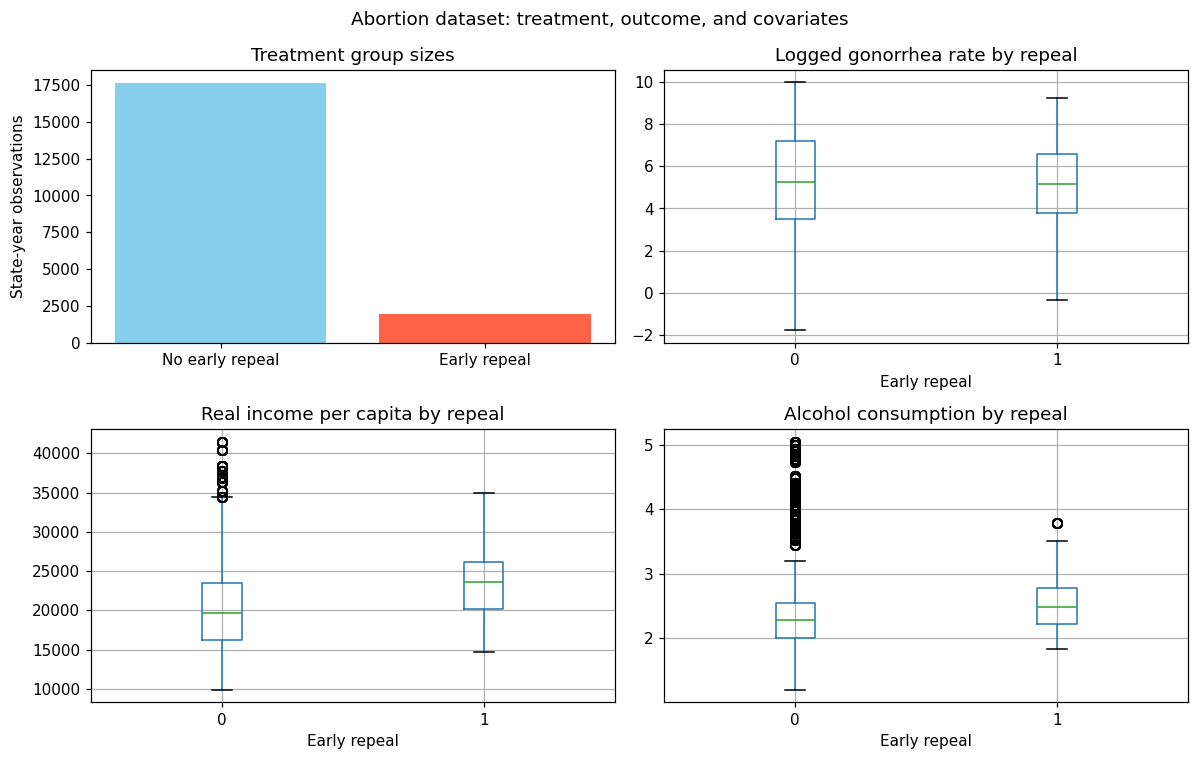

In [4]:
print(abortion_df.head())
print(abortion_df["repeal"].value_counts().sort_index())
print(pd.crosstab(abortion_df["repeal"], abortion_df["race"]))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
counts = abortion_df["repeal"].value_counts().sort_index()
axes[0, 0].bar(["No early repeal", "Early repeal"], counts.to_numpy(), color=["skyblue", "tomato"])
axes[0, 0].set_title("Treatment group sizes")
axes[0, 0].set_ylabel("State-year observations")
abortion_df.boxplot(column="lnr", by="repeal", ax=axes[0, 1])
axes[0, 1].set_title("Logged gonorrhea rate by repeal")
axes[0, 1].set_xlabel("Early repeal")
abortion_df.boxplot(column="income", by="repeal", ax=axes[1, 0])
axes[1, 0].set_title("Real income per capita by repeal")
axes[1, 0].set_xlabel("Early repeal")
abortion_df.boxplot(column="alcohol", by="repeal", ax=axes[1, 1])
axes[1, 1].set_title("Alcohol consumption by repeal")
axes[1, 1].set_xlabel("Early repeal")
fig.suptitle("Abortion dataset: treatment, outcome, and covariates")
fig.tight_layout()
plt.show()


### Data processing

We restrict to the 15–19 age group and drop rows with any missing values, then define covariate matrix $X$, outcome $Y$, and treatment $W$.

In [5]:
missing_rate = abortion_df.isna().mean()
sparse = missing_rate[missing_rate >= 0.2].index.tolist()
print("Dropped sparse columns:", sparse)
model_df = abortion_df.drop(columns=sparse).dropna().reset_index(drop=True)
feature_names = [c for c in model_df.columns if c not in {"lnr", "repeal"}]
X = model_df[feature_names].to_numpy(dtype=float)
Y = model_df["lnr"].to_numpy(dtype=float)
W = model_df["repeal"].to_numpy(dtype=int)
keep = np.var(X, axis=0) > 1e-10
X = X[:, keep]
feature_names = [name for name, flag in zip(feature_names, keep) if flag]
x_names = feature_names
print("Covariates used:", x_names)
print("n =", len(Y), " treated =", int(W.sum()))


Dropped sparse columns: ['fa']
Covariates used: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']
n = 17921  treated = 1854


### Train / test split

We use an 80 / 20 random split (seed fixed for reproducibility).

In [6]:
rng_abortion = np.random.default_rng(42)
n = len(Y)
train_idx = rng_abortion.choice(n, size=round(0.8 * n), replace=False)
test_idx = np.setdiff1d(np.arange(n), train_idx)
X_train, X_test = X[train_idx], X[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]
W_train, W_test = W[train_idx], W[test_idx]
print("Training rows:", len(Y_train))
print("Test rows:    ", len(Y_test))
print("Columns:      ", x_names)


Training rows: 14337
Test rows:     3584
Columns:       ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']


Outcome by treatment arm:

In [7]:
arm = pd.DataFrame({"lnr": Y, "repeal": W})
summary = arm.groupby("repeal")["lnr"].agg(mean="mean", sd="std", size="size")
summary.loc["All"] = [float(Y.mean()), float(Y.std()), len(Y)]
print(summary.round(4))


          mean      sd     size
repeal                         
0       5.3031  2.1617  16067.0
1       5.1234  1.8227   1854.0
All     5.2845  2.1297  17921.0


### Feature selection (F-filter)

Following Zhao et al. (2020), each covariate is ranked by the partial F statistic of its interaction with treatment in a linear model of `lnr`. Order 1 tests `lnr ~ x + repeal + x:repeal`. Orders 2 and 3 add higher powers of `x`. Ranking uses the training rows only.

The likelihood-ratio and KL filters in the uplift literature are for binary outcomes. `lnr` is continuous, so the F-filter is the matching choice.


In [8]:
print("Training matrix:", X_train.shape)


Training matrix: (14337, 19)


In [9]:
f_imp_1 = f_filter(X_train, Y_train, W_train, x_names, order=1)
f_imp_2 = f_filter(X_train, Y_train, W_train, x_names, order=2)
f_imp_3 = f_filter(X_train, Y_train, W_train, x_names, order=3)
print("*** Order 1 ***")
print(f_imp_1.head(8).round(3).to_string(index=False))
print("*** Order 2 ***")
print(f_imp_2.head(8).round(3).to_string(index=False))
print("*** Order 3 ***")
print(f_imp_3.head(8).round(3).to_string(index=False))


*** Order 1 ***
feature   score
 totpop 347.665
    wht 127.510
   race 127.510
alcohol  61.162
    acc  56.732
poverty  33.773
 income  25.682
      t   6.779
*** Order 2 ***
feature   score
 totpop 249.348
    wht  64.489
   race  64.489
     ir  52.212
alcohol  31.556
poverty  22.873
    acc  19.134
  crack  16.721
*** Order 3 ***
feature   score
 totpop 114.004
    wht  40.778
   race  40.778
     ir  37.056
alcohol  25.219
poverty  17.190
  crack  15.476
    acc  15.135


#### Feature importance plot

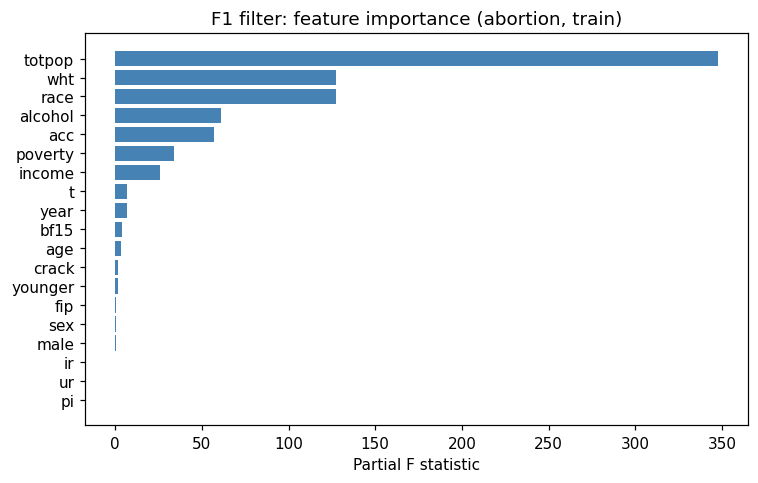

In [10]:
top_bar = f_imp_1.head(min(20, len(f_imp_1))).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_bar["feature"], top_bar["score"], color="steelblue")
ax.set_xlabel("Partial F statistic")
ax.set_title("F1 filter: feature importance (abortion, train)")
fig.tight_layout()
plt.show()


#### Define feature subsets

In [11]:
ranked_f = f_imp_1["feature"].tolist()
top_3_features = ranked_f[: min(3, len(ranked_f))]
top_6_features = ranked_f[: min(6, len(ranked_f))]
print("Top 3 (F1):", ", ".join(top_3_features))
print("Top 6 (F1):", ", ".join(top_6_features))


Top 3 (F1): totpop, wht, race
Top 6 (F1): totpop, wht, race, alcohol, acc, poverty


### Comparing Learners across Feature Subsets

We compare **cumulative gain** and **AUUC** (area under the uplift curve, normalised) on the test set for T-, R-, and S-learners fitted on all features, the top-6 subset, and the top-3 subset.

In [12]:
def fit_learner(Learner, feats, **kwargs):
    cols = [x_names.index(name) for name in feats]
    model = Learner(**kwargs)
    model.fit(X_train[:, cols], W_train, Y_train, feature_names=list(feats))
    return model.predict(X_test[:, cols])

feature_sets = {
    "All": x_names,
    "Top_3": top_3_features,
    "Top_6": top_6_features,
}


### T-Learner

In [13]:
pred_tl = {
    name: fit_learner(TLearner, feats, learner="rf", n_estimators=25, random_state=111)
    for name, feats in feature_sets.items()
}
pred_tl["Random"] = np.random.default_rng(42).random(len(Y_test))


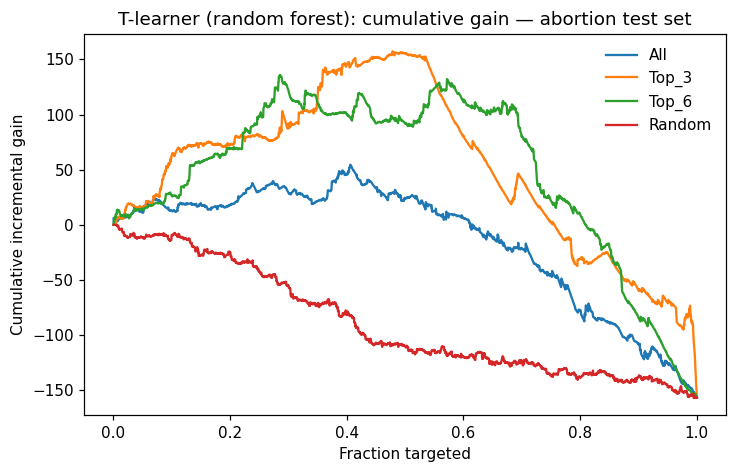

    model      qini
0     All   64.6598
1   Top_3  129.1078
2   Top_6  125.7647
3  Random  -11.4375


In [14]:
fig, auuc_tl = plot_qini_models(
    Y_test, W_test, pred_tl, title="T-learner (random forest): cumulative gain — abortion test set"
)
plt.show()
print(auuc_tl.round(4))


### R-Learner

In [15]:
pred_rl = {
    name: fit_learner(RLearner, feats, learner="rf", n_estimators=15, n_splits=2, random_state=111)
    for name, feats in feature_sets.items()
}
pred_rl["Random"] = np.random.default_rng(42).random(len(Y_test))


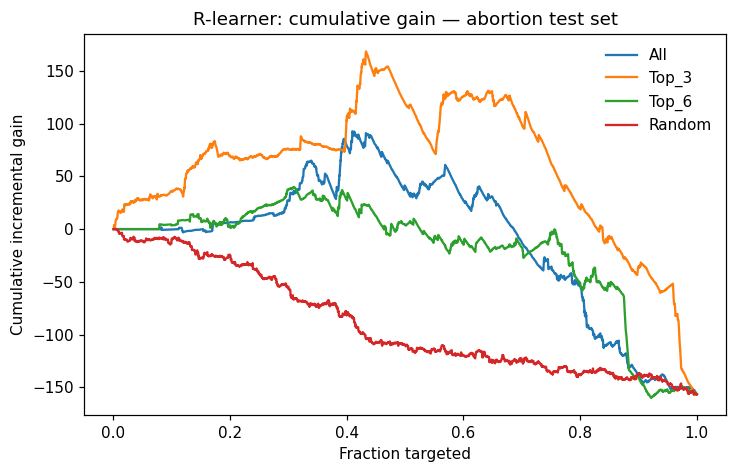

    model      qini
0     All   68.5975
1   Top_3  136.1678
2   Top_6   58.4407
3  Random  -11.4375


In [16]:
fig, auuc_rl = plot_qini_models(
    Y_test, W_test, pred_rl, title="R-learner: cumulative gain — abortion test set"
)
plt.show()
print(auuc_rl.round(4))


### S-Learner

In [17]:
pred_sl = {
    name: fit_learner(SLearner, feats, learner="rf", n_estimators=25, random_state=111)
    for name, feats in feature_sets.items()
}
pred_sl["Random"] = np.random.default_rng(42).random(len(Y_test))


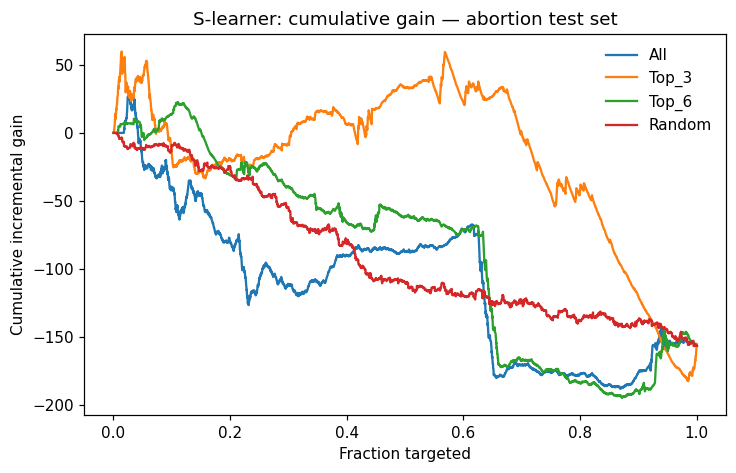

    model     qini
0     All -31.8943
1   Top_3  59.0114
2   Top_6  -7.9036
3  Random -11.4375


In [18]:
fig, auuc_sl = plot_qini_models(
    Y_test, W_test, pred_sl, title="S-learner: cumulative gain — abortion test set"
)
plt.show()
print(auuc_sl.round(4))


### AUUC summary table

In [19]:
auuc_tab = pd.concat([
    auuc_tl.assign(learner="T-learner"),
    auuc_rl.assign(learner="R-learner"),
    auuc_sl.assign(learner="S-learner"),
], ignore_index=True)
print(auuc_tab.round(4).to_string(index=False))


 model     qini   learner
   All  64.6598 T-learner
 Top_3 129.1078 T-learner
 Top_6 125.7647 T-learner
Random -11.4375 T-learner
   All  68.5975 R-learner
 Top_3 136.1678 R-learner
 Top_6  58.4407 R-learner
Random -11.4375 R-learner
   All -31.8943 S-learner
 Top_3  59.0114 S-learner
 Top_6  -7.9036 S-learner
Random -11.4375 S-learner


> **Reading the table:** Higher AUUC means better uplift ranking. Smaller feature sets can match or beat "all features" when the dropped covariates are noisy — this is the practical payoff of filter-based feature selection.

## Uplift random forest

`UpliftRandomForest` bags trees that split on treatment-effect heterogeneity. On a continuous outcome the split is the squared difference of child CATEs, the same rule as `InteractionTree`. `TLearner(learner="rf")` is the two-forest T-learner: one random forest per arm, and CATE equals the difference of predicted means.

### T-learner forest


In [20]:
uplift_model = TLearner(learner="rf", n_estimators=40, random_state=111)
uplift_model.fit(X_train, W_train, Y_train, feature_names=x_names)
pred_tr = uplift_model.predict(X_train)
pred_te = uplift_model.predict(X_test)
print(
    "Mean predicted CATE — train:", round(float(pred_tr.mean()), 4),
    "| test:", round(float(pred_te.mean()), 4),
)


Mean predicted CATE — train: -0.1332 | test: -0.1184


The `full_output = TRUE` argument returns the control arm prediction, treatment arm prediction, and CATE (delta) for each unit — useful for auditing and downstream analysis.

In [21]:
pred_full = pd.DataFrame({
    "control": uplift_model.mu0_.predict(X_test),
    "treated": uplift_model.mu1_.predict(X_test),
    "cate": pred_te,
})
pred_full.head()


,control,treated,cate
0,5.405646,4.669976,-0.735670
1,5.742501,5.758414,0.015913
2,5.389370,4.651757,-0.737613
3,8.248191,7.670827,-0.577364
4,3.914643,4.237091,0.322448


### Uplift forest (treatment-effect splits)

`UpliftRandomForest` averages leaf contrasts from trees that split to separate treatment effects, rather than fitting two outcome models.


In [22]:
uplift_it_rf = UpliftRandomForest(
    criterion="ed", n_trees=12, max_depth=4, min_samples_leaf=60, random_state=111
)
uplift_it_rf.fit(X_train, W_train, Y_train, feature_names=x_names)
pred_it_te = uplift_it_rf.predict(X_test)
print("Uplift forest — mean predicted CATE (test):", round(float(pred_it_te.mean()), 4))


Uplift forest — mean predicted CATE (test): -0.0726


Model summaries:

In [23]:
print("T-learner importances:")
print(pd.Series(
    0.5 * (uplift_model.mu0_.feature_importances_ + uplift_model.mu1_.feature_importances_),
    index=x_names,
).sort_values(ascending=False).round(4).head(8))
print("Uplift-forest importances:")
print(pd.Series(uplift_it_rf.feature_importance(), index=x_names).sort_values(ascending=False).round(4).head(8))


T-learner importances:
wht        0.3722
race       0.3411
age        0.1569
income     0.0285
alcohol    0.0236
sex        0.0175
male       0.0158
year       0.0116
dtype: float64
Uplift-forest importances:
totpop     0.3897
ir         0.1909
fip        0.1742
alcohol    0.0805
poverty    0.0749
acc        0.0185
ur         0.0181
race       0.0161
dtype: float64


## Evaluation

### Gain curve on the test set

The **cumulative gain curve** plots, as we move through units in descending order of predicted CATE, how much *actual* treatment benefit we capture relative to random assignment. A curve bowing above the diagonal indicates useful uplift ranking.

In [24]:
df_gain = pd.DataFrame({
    "is_treated": W_test,
    "outcome": Y_test,
    "uplift_model": pred_te,
})
df_gain.head()


,is_treated,outcome,uplift_model
0,0,6.362165,-0.735670
1,0,6.135781,0.015913
2,0,5.544787,-0.737613
3,0,8.268040,-0.577364
4,0,4.560173,0.322448


Qini coefficient: 62.6804


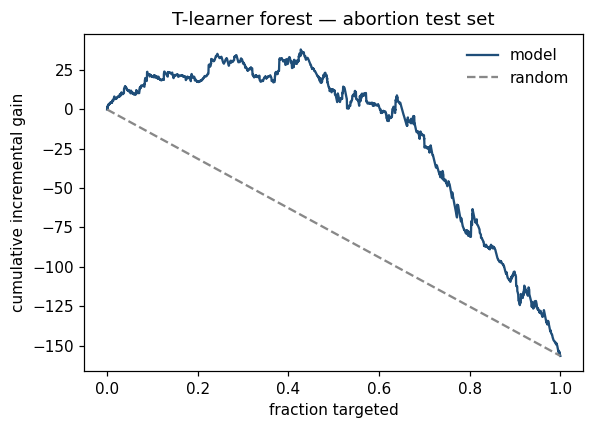

In [25]:
plot_uplift_curve(Y_test, W_test, pred_te, title="T-learner forest — abortion test set")
print("Qini coefficient:", round(qini_coefficient(Y_test, W_test, pred_te), 4))
plt.show()


#### Distribution of predicted CATE

Fitting on the **full dataset** gives a picture of how heterogeneous the treatment effect is across all observed covariate profiles.

In [26]:
uf_full = TLearner(learner="rf", n_estimators=30, random_state=111)
uf_full.fit(X, W, Y, feature_names=x_names)
pred_cate_full = uf_full.predict(X)


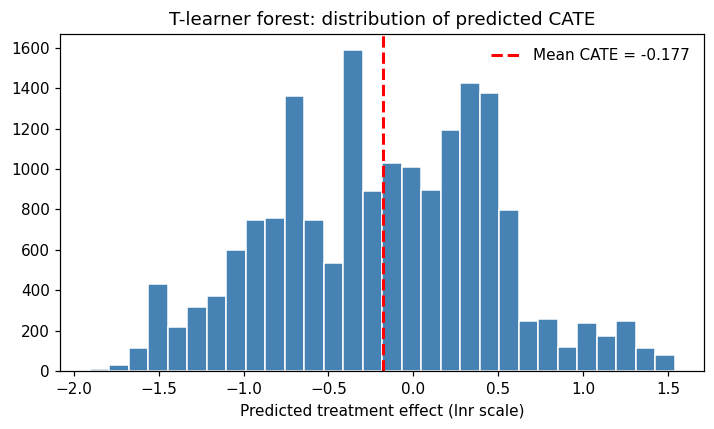

In [27]:
fig, ax = plt.subplots(figsize=(6.6, 4))
ax.hist(pred_cate_full, bins=30, color="steelblue", edgecolor="white")
ax.axvline(pred_cate_full.mean(), color="red", ls="--", lw=2)
ax.set_xlabel("Predicted treatment effect (lnr scale)")
ax.set_title("T-learner forest: distribution of predicted CATE")
ax.legend([f"Mean CATE = {pred_cate_full.mean():.3f}"], frameon=False)
fig.tight_layout()
plt.show()


### Variable importance

For the T-learner, average the impurity importance of the control forest and the treated forest. The uplift forest reports split-gain importance from `feature_importance`. Individual uplift trees are drawn from `uplift_it_rf.trees_`.


wht        0.3722
race       0.3411
age        0.1569
income     0.0285
alcohol    0.0236
sex        0.0175
male       0.0158
year       0.0116
dtype: float64


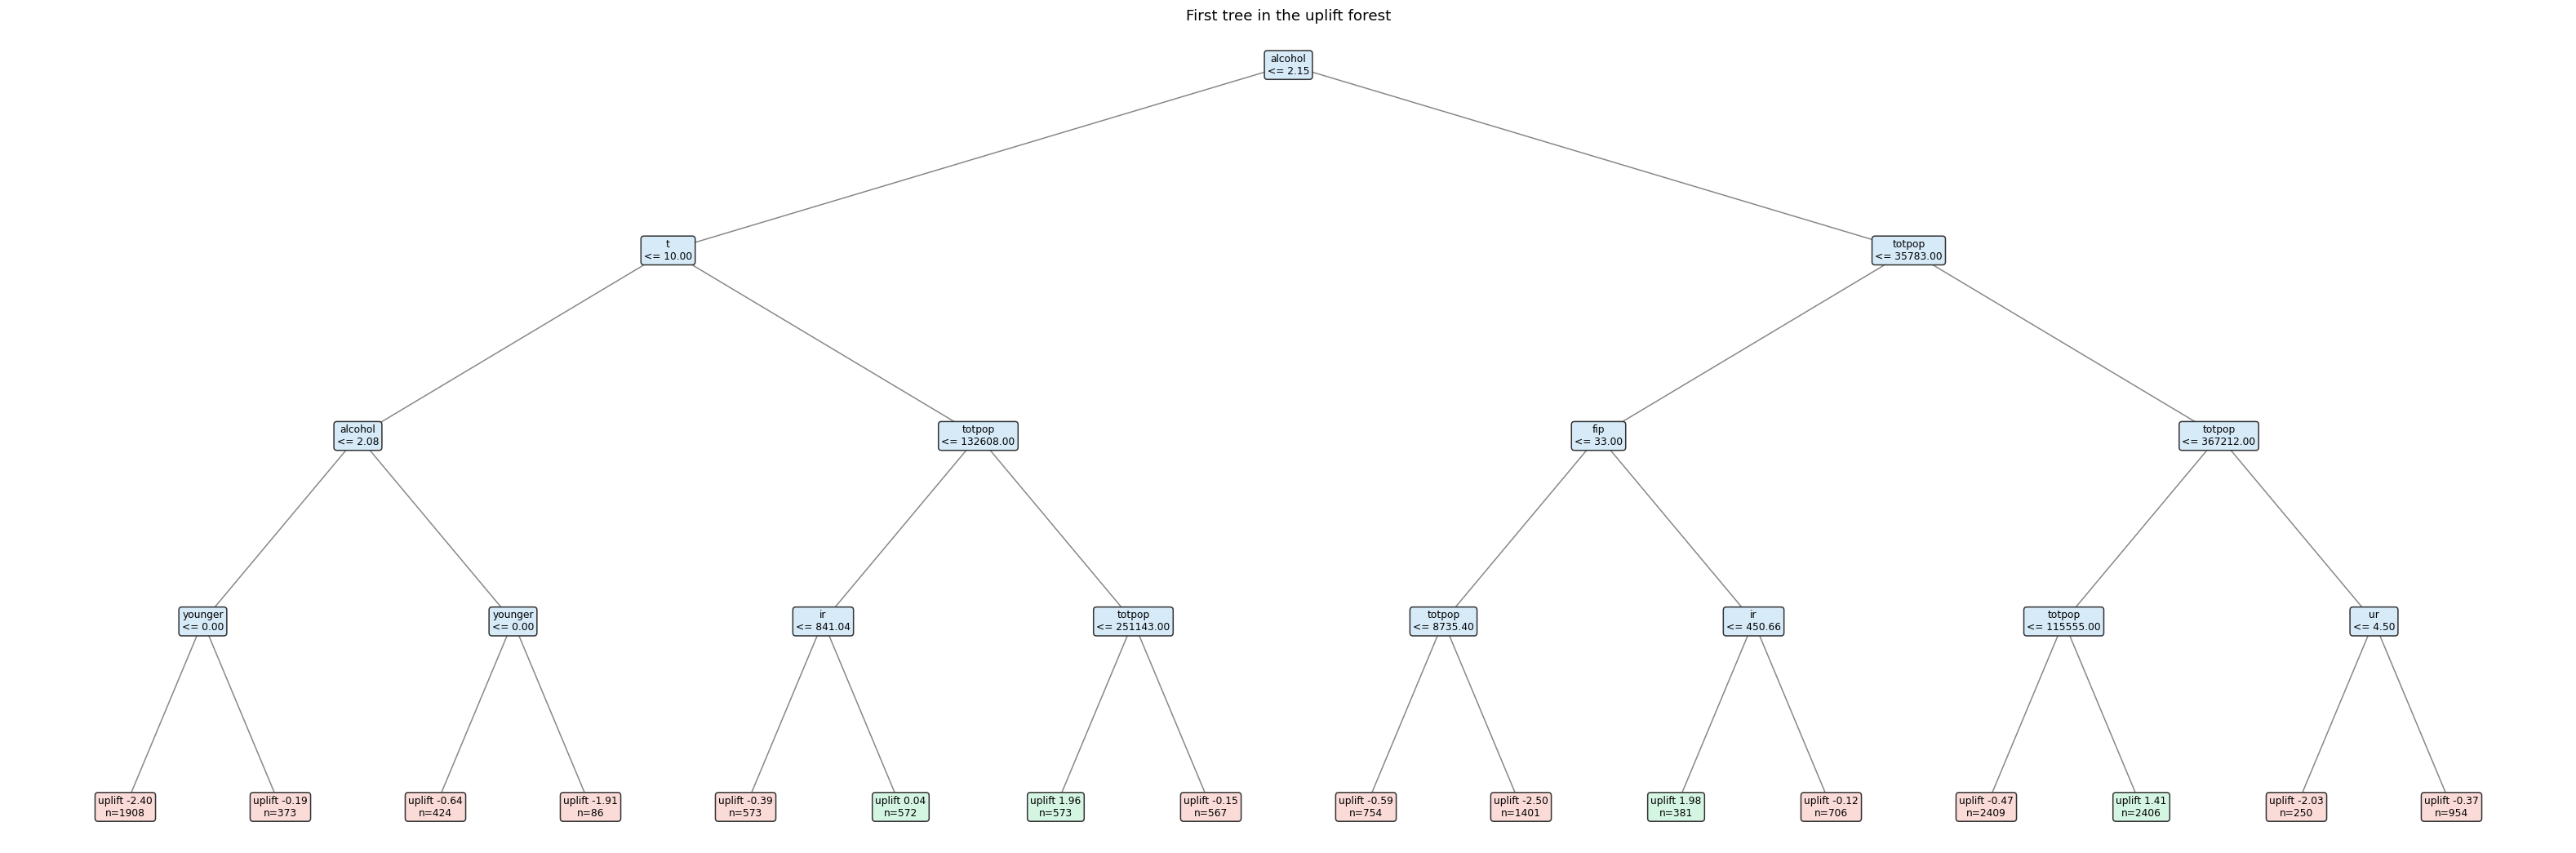

In [28]:
imp_avg = 0.5 * (
    np.asarray(uplift_model.mu0_.feature_importances_)
    + np.asarray(uplift_model.mu1_.feature_importances_)
)
print(pd.Series(imp_avg, index=x_names).sort_values(ascending=False).round(4).head(8))
plot_uplift_tree(uplift_it_rf.trees_[0], title="First tree in the uplift forest")
plt.show()


## Interpretable Single-Tree Models

Forests are powerful but opaque. A single **interaction tree** or **causal inference tree** summarises the learned heterogeneity in human-readable split rules, useful for communicating findings to non-technical stakeholders.

### Interaction tree (IT)

In [29]:
it_fit = InteractionTree(max_depth=3, min_samples_leaf=80, random_state=111)
it_fit.fit(X_train, W_train, Y_train, feature_names=x_names)
print(format_uplift_tree(it_fit))


[alcohol <= 2.150]  gain=3348.7738  tau=-0.119  n=14337
  [poverty <= 13.700]  gain=865.0966  tau=-0.965  n=5045
    [wht <= 0.000]  gain=500.3254  tau=-0.367  n=2574
      * leaf  tau=-0.836  n=1268
      * leaf  tau=0.046  n=1306
    [ir <= 139.480]  gain=465.2184  tau=-1.195  n=2471
      * leaf  tau=-1.442  n=866
      * leaf  tau=-0.533  n=1605
  [totpop <= 36115.000]  gain=3088.1481  tau=0.047  n=9292
    [fip <= 33.000]  gain=2099.1684  tau=-0.947  n=3253
      * leaf  tau=-1.354  n=2185
      * leaf  tau=0.357  n=1068
    [alcohol <= 2.720]  gain=1450.1082  tau=0.262  n=6039
      * leaf  tau=-0.076  n=4871
      * leaf  tau=1.165  n=1168


Leaf labels show $\hat{\tau} \approx \mathbb{E}[Y \mid T=1] - \mathbb{E}[Y \mid T=0]$ within each region.

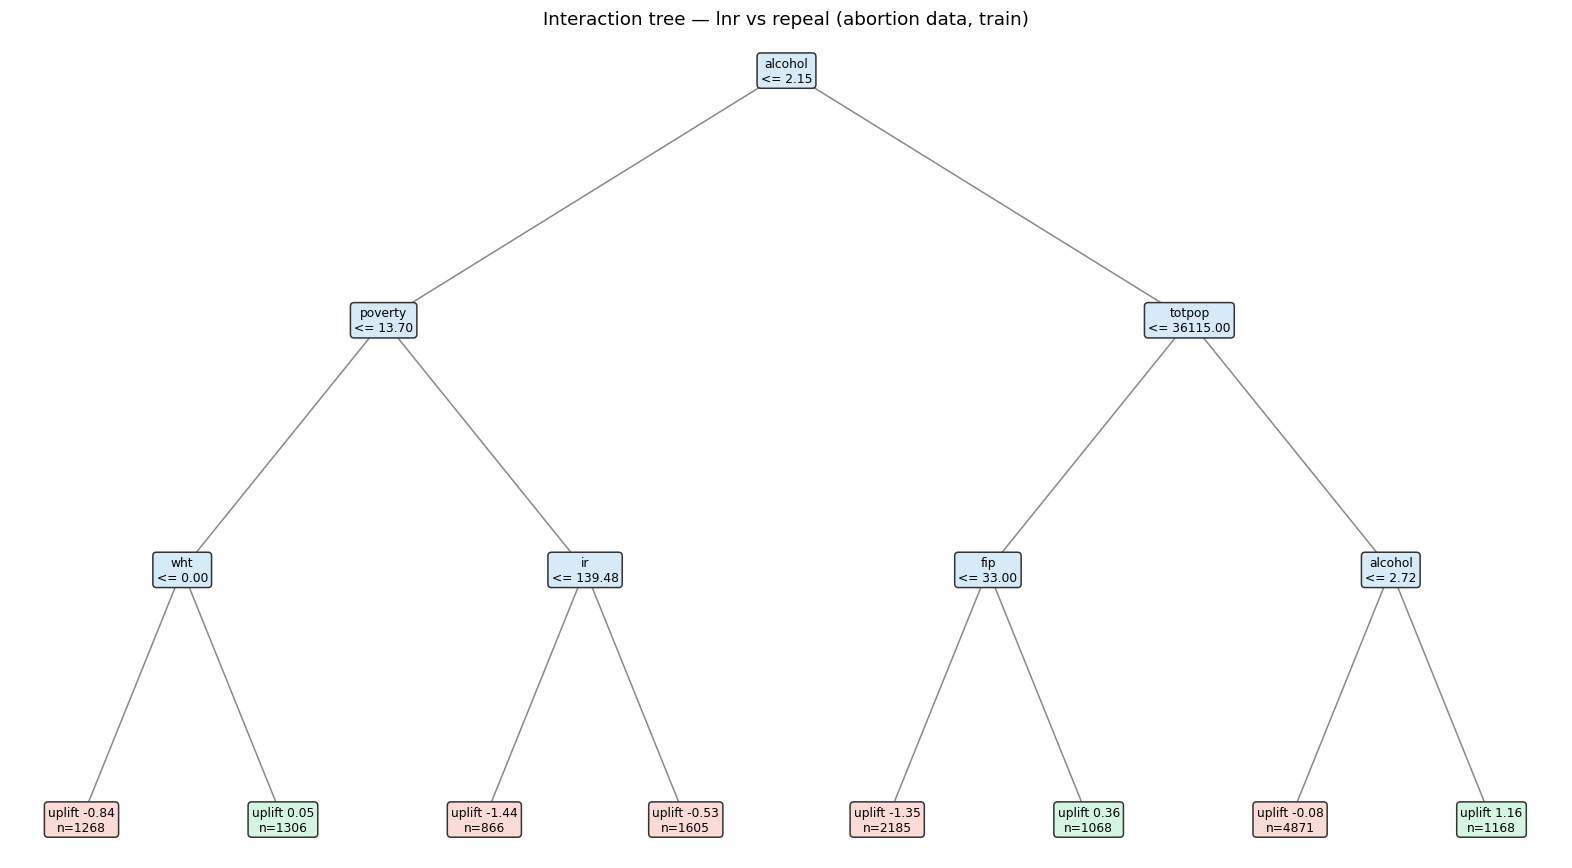

In [30]:
plot_uplift_tree(it_fit, title="Interaction tree — lnr vs repeal (abortion data, train)")
plt.show()


### Causal inference tree (CIT)

    cate     n                                         conditions
0  1.406   797                     acc <= 5.919 AND race <= 1.000
1 -0.649   172  acc <= 5.919 AND race > 1.000 AND year <= 1985...
2 -0.571   402  acc <= 5.919 AND race > 1.000 AND year > 1985.000
3 -1.108  1904  acc > 5.919 AND totpop <= 132551.040 AND fip <...
4  0.916  1366  acc > 5.919 AND totpop <= 132551.040 AND fip >...
5  1.878  1398  acc > 5.919 AND totpop > 132551.040 AND totpop...
6 -0.207  1129  acc > 5.919 AND totpop > 132551.040 AND totpop...


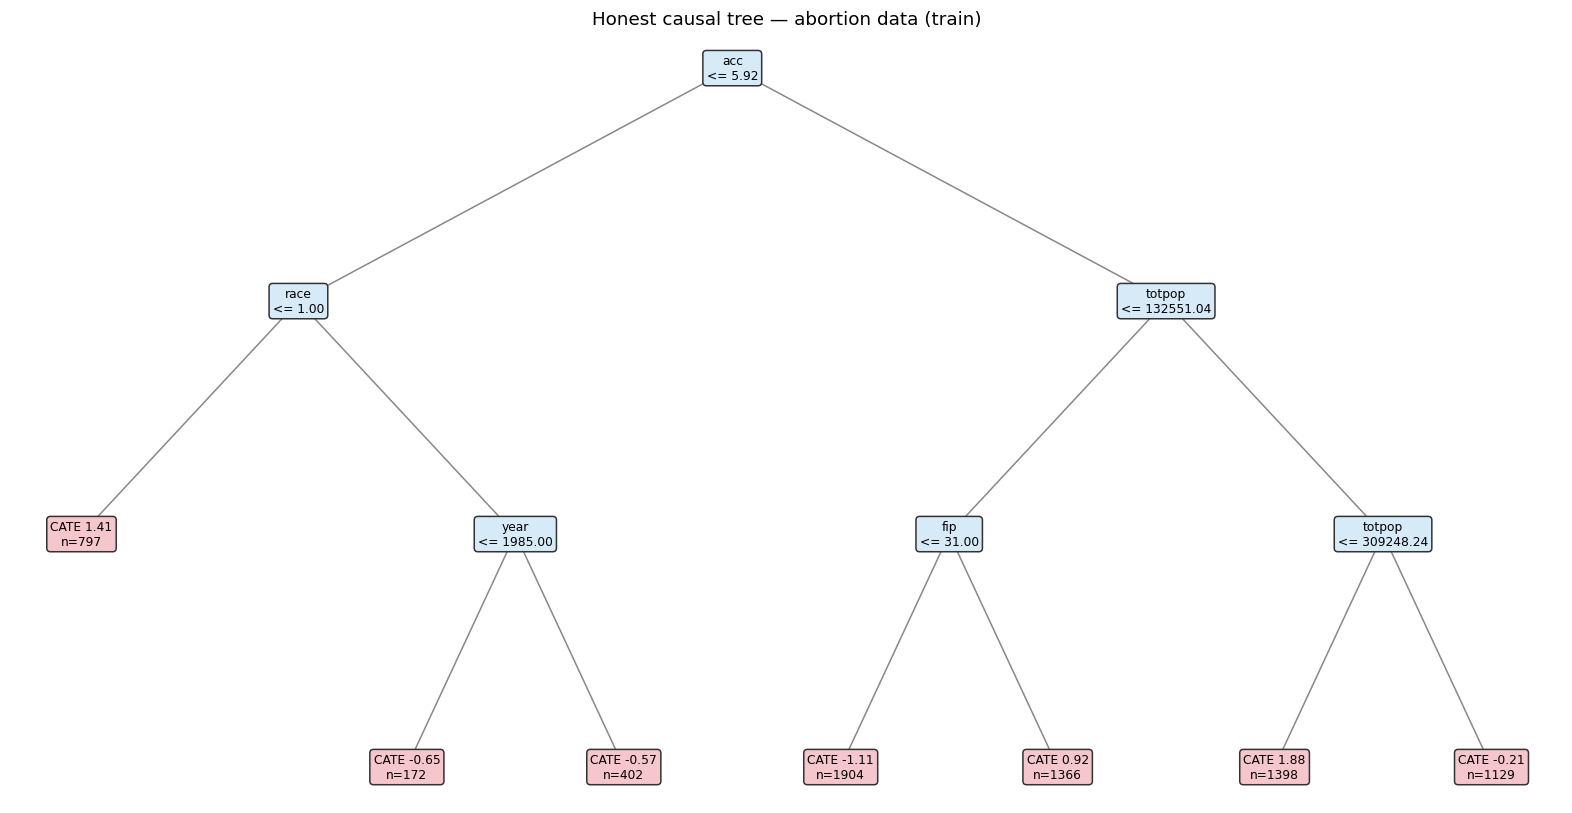

In [31]:
cit_fit = CausalTree(max_depth=3, min_samples_leaf=80, honest=True, random_state=111)
cit_fit.fit(X_train, W_train, Y_train, feature_names=x_names)
print(pd.DataFrame(cit_fit.rules()).round(3))
plot_causal_tree(cit_fit, title="Honest causal tree — abortion data (train)")
plt.show()


## Explaining predicted CATE

`explain` decomposes predicted CATE into covariate contributions. A positive value means that feature pushes the predicted treatment effect up. The explanation is about $\hat{\tau}(X)$, not the raw outcome. The call below uses a subset of the training rows.


In [32]:
sv = uplift_model.explain(X_train, max_samples=24, n_permutations=4, random_state=2026)
print("SHAP array shape:", sv.values.shape)


SHAP array shape:

 (24, 19)


### Global feature importance

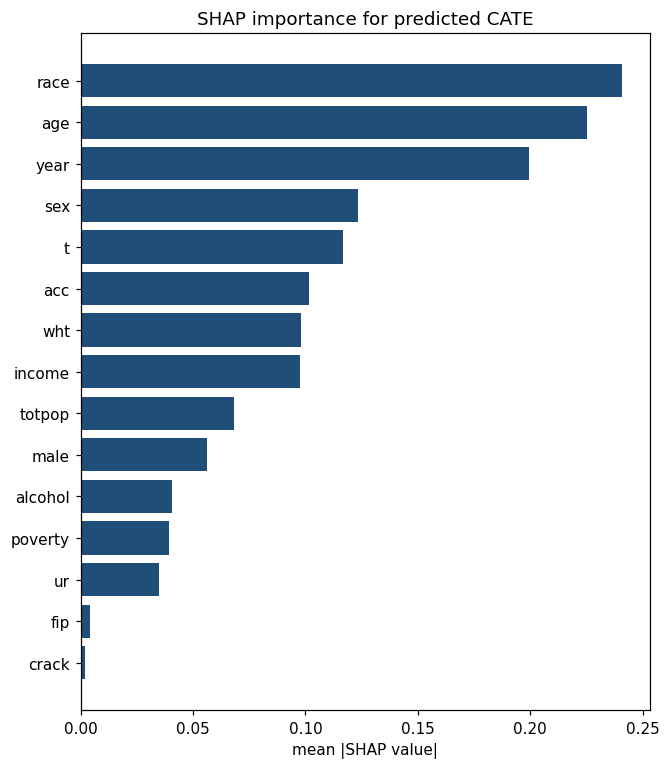

In [33]:
sv.plot_importance(title="SHAP importance for predicted CATE")
plt.show()


### Dependence plots

These show how a feature's SHAP value changes as the feature value changes — revealing the shape of the heterogeneity.

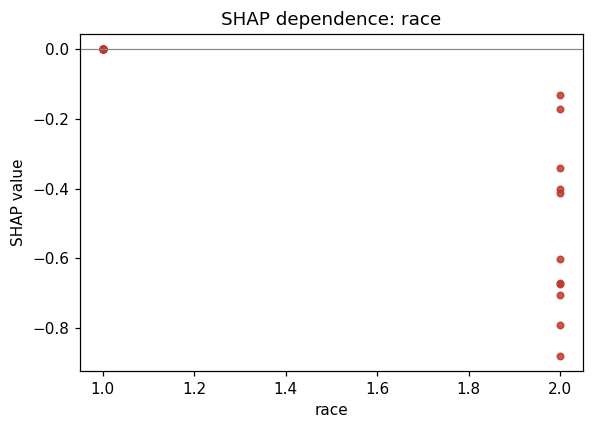

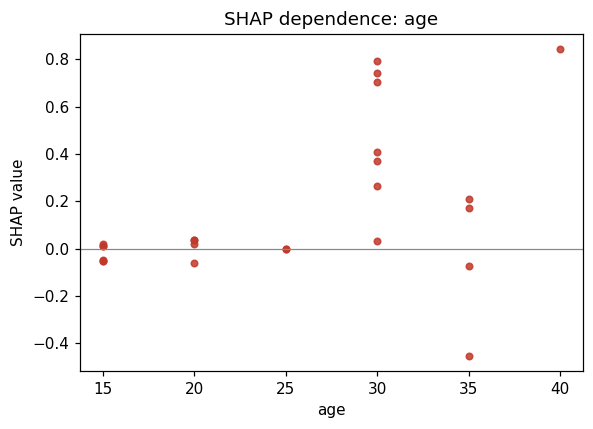

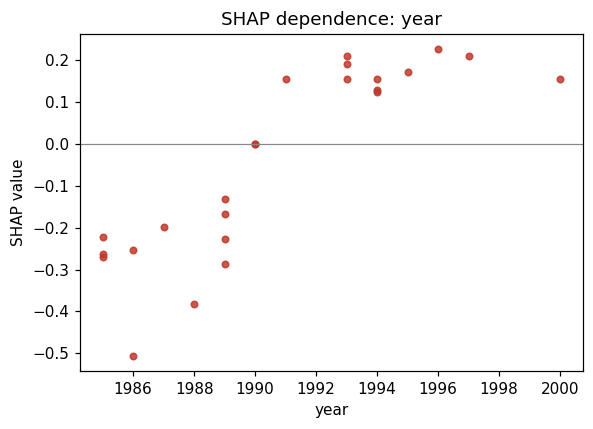

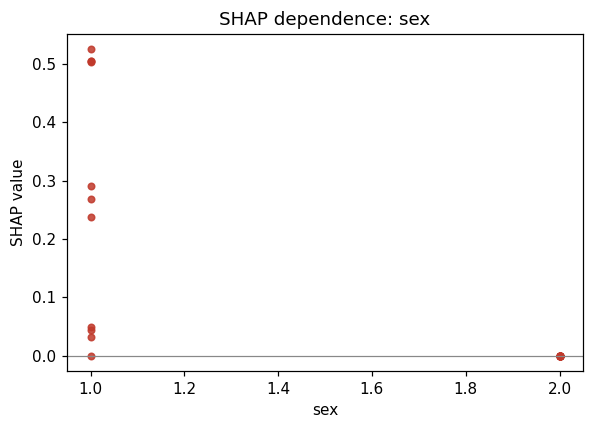

In [34]:
order = np.argsort(sv.importance())[::-1][:4]
for feature in np.asarray(x_names)[order]:
    sv.plot_dependence(feature)
    plt.show()


Interaction between the top two features:

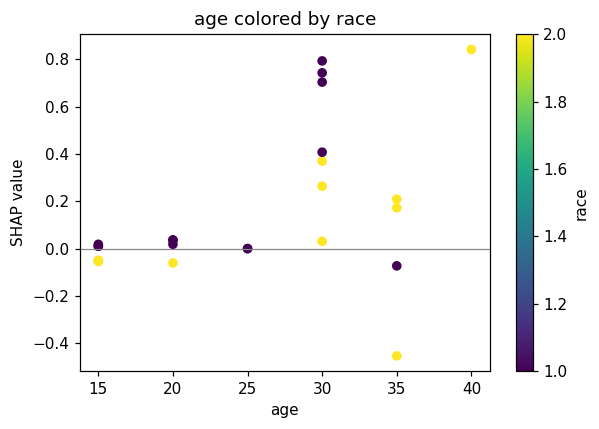

In [35]:
if len(order) >= 2:
    j, k = int(order[1]), int(order[0])
    fig, ax = plt.subplots(figsize=(5.6, 4))
    points = ax.scatter(sv.data[:, j], sv.values[:, j], c=sv.data[:, k], cmap="viridis", s=28)
    fig.colorbar(points, ax=ax, label=x_names[k])
    ax.axhline(0, color="#888888", lw=0.8)
    ax.set_xlabel(x_names[j])
    ax.set_ylabel("SHAP value")
    ax.set_title(f"{x_names[j]} colored by {x_names[k]}")
    fig.tight_layout()
    plt.show()


### Waterfall plot: highest-uplift unit

A waterfall plot decomposes one unit's predicted CATE into covariate contributions, starting from the baseline (mean prediction across background) and adding or subtracting each feature's SHAP value.

Highest predicted CATE in the explain set: 0.6571


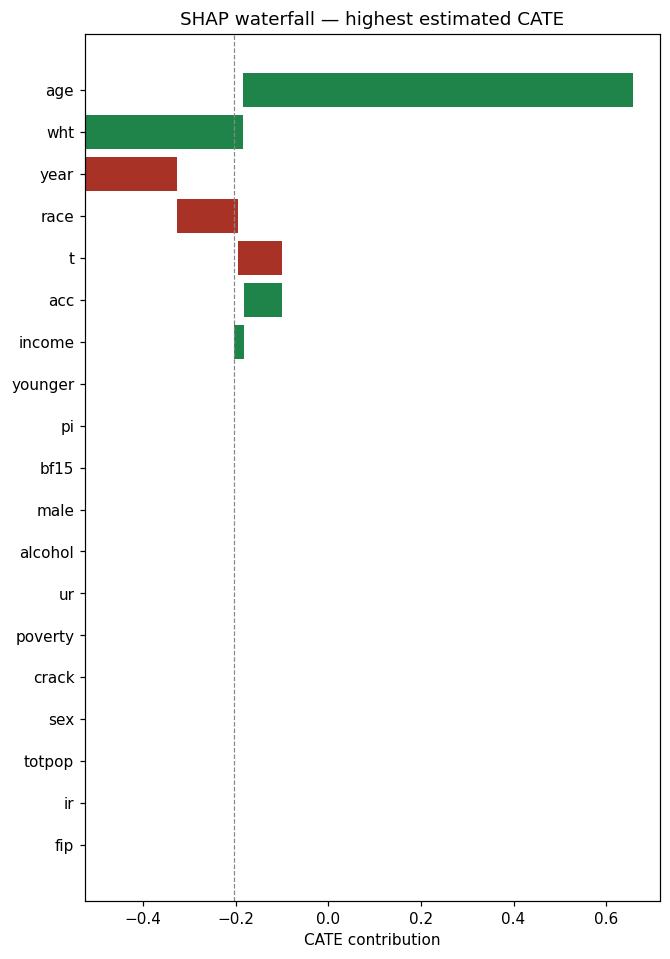

In [36]:
row_id = int(np.argmax(sv.predictions))
print("Highest predicted CATE in the explain set:", round(float(sv.predictions[row_id]), 4))
sv.plot_waterfall(row_id, title="SHAP waterfall — highest estimated CATE")
plt.show()


### SHAP on the test set

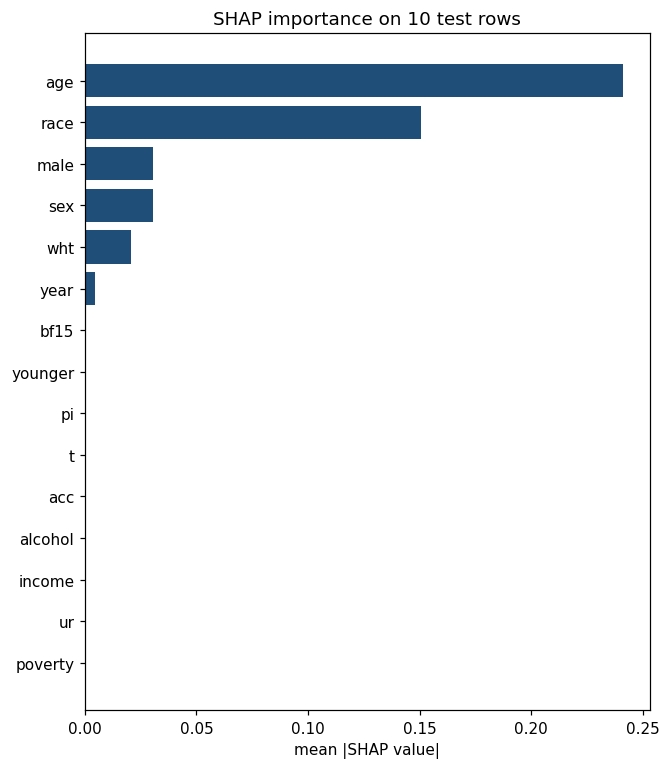

In [37]:
sv_test = uplift_model.explain(X_test[:10], max_samples=10, n_permutations=4, random_state=2026)
sv_test.plot_importance(title="SHAP importance on 10 test rows")
plt.show()


## Summary

This tutorial walks through uplift regression on the abortion dataset with PyCausalML.

| Step | What we did |
|------|-------------|
| **Data** | Loaded `abortion` from `causaldata`, as in the causal-tree tutorial. Outcome `lnr`, treatment `repeal` |
| **Feature selection** | F-filter on the training rows; compared top-3, top-6, and all features |
| **Learner comparison** | T-, R-, and S-learners scored by the Qini coefficient on the test set |
| **Uplift forest** | `TLearner` random forests and `UpliftRandomForest` |
| **Evaluation** | Qini curves, CATE distribution, feature importance |
| **Single trees** | `InteractionTree` and honest `CausalTree` |
| **SHAP** | `explain` — importance, dependence, and a waterfall plot |

### Key reminders

- **Scale of CATE:** predictions are on the `lnr` scale. A CATE of $-0.10$ is 0.10 fewer log-points of gonorrhea rate.
- **Observational data:** the forest estimates conditional contrasts. Identification is a separate argument.
- **T-learner vs uplift forest:** `TLearner(learner="rf")` fits two outcome forests. `UpliftRandomForest` splits on treatment-effect heterogeneity and keeps the individual trees.


## Resources

- [Uplift Trees Example — Python CausalML docs](https://causalml.readthedocs.io/en/latest/examples/uplift_trees_with_synthetic_data.html)
- [Feature Selection for Uplift Modelling — Python CausalML docs](https://causalml.readthedocs.io/en/latest/examples/feature_selection.html)
- Zhao, Z., Feng, T., Garg, V., & Cakmak, M. (2020). [Feature Selection Methods for Uplift Modeling](https://arxiv.org/abs/2005.03447). *arXiv*.
- Gutierrez, P., & Gérardy, J.-Y. (2017). [Causal inference and uplift modelling: A review of the literature](http://proceedings.mlr.press/v67/gutierrez17a/gutierrez17a.pdf). *PMLR*.
- Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32.